In [4]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import cv2
import os

%matplotlib inline

In [24]:
# Paths - update for your image
IMAGE_NAME = 'bed_back_bedroom'
BASE_PATH = Path(f'../rgb-x_output/batch_output/')


normal_path = BASE_PATH / f"{IMAGE_NAME}_normal.npy"
rgb_path = BASE_PATH / f"{IMAGE_NAME}.jpg"

In [25]:
IMAGE_NAME = 'bed_back_bedroom'
normal_path = BASE_PATH / IMAGE_NAME / f"{IMAGE_NAME}_normal_preview.png"
img_path = BASE_PATH / IMAGE_NAME / f"{IMAGE_NAME}.jpg"
wall_conf_path = BASE_PATH / IMAGE_NAME / f"{IMAGE_NAME}_wall_confidence.npy"
if(os.path.exists(img_path)):
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert to RGB for display
    print("RGB Image Shape: ", img.shape)

nor_img = cv2.imread(str(normal_path))
print("Shape: ", nor_img.shape)

# Reshape to (num_pixels, 3) to treat each pixel as an RGB triplet
pixels = nor_img.reshape(-1, 3)
total_pixels = pixels.shape[0]

# Find unique RGB combinations
unique_colors = np.unique(pixels, axis=0)
num_unique = len(unique_colors)

# Calculate percentage of unique pixels
percentage_unique = (num_unique / total_pixels) * 100

print(f"{IMAGE_NAME} - Shape: {nor_img.shape}")
print(f"Total pixels: {total_pixels}")
print(f"Unique RGB combinations: {num_unique}")
print(f"Percentage of unique colors: {percentage_unique:.2f}%")

RGB Image Shape:  (700, 1200, 3)
Shape:  (700, 1200, 3)
bed_back_bedroom - Shape: (700, 1200, 3)
Total pixels: 840000
Unique RGB combinations: 252667
Percentage of unique colors: 30.08%


## Clustering Normal Map using KMeans

In [26]:
import numpy as np
from sklearn.cluster import KMeans
import cv2
from PIL import Image

# Load image
img = cv2.imread(str(img_path))

# Reshape to 2D array of pixels
pixels = nor_img.reshape(-1, 3)

# Apply KMeans (e.g., 5 color clusters)
kmeans = KMeans(n_clusters=20, random_state=42)
labels = kmeans.fit_predict(pixels)

# Replace each pixel with its cluster center
clustered_img = kmeans.cluster_centers_[labels]
clustered_img = clustered_img.reshape(img.shape).astype(np.uint8)

kmeans.cluster_centers_

/Users/ishan-aiworkspace/Documents/apps/rgb-x/Notebook for Output visualisation/venv_notebook/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ishan-aiworkspace/Documents/apps/rgb-x/Notebook for Output visualisation/venv_notebook/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ishan-aiworkspace/Documents/apps/rgb-x/Notebook for Output visualisation/venv_notebook/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ishan-aiworkspace/Documents/apps/rgb-x/Notebook for Output visualisation/venv_notebook/lib/python3.13/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/ishan-aiworkspace/Documents/apps/rgb-x/Notebook for Output visualisation/venv_notebo

array([[219.04130013, 137.99696253, 206.6904374 ],
       [207.49446012, 136.57204908,  35.83309932],
       [116.8130074 , 247.47861188, 129.17371722],
       [148.63528162,   3.4235565 , 128.02026213],
       [239.57530846, 138.43387   , 139.85784683],
       [173.94266768, 203.20239   ,  51.78130828],
       [196.98022312, 160.81118999, 210.9824769 ],
       [177.3136836 , 213.12741575, 177.04787802],
       [192.51862034, 100.64783804,  45.22381905],
       [215.75759089, 193.71973632, 118.68567719],
       [242.37235433, 138.53996514, 107.34474602],
       [137.98362843, 238.12281242, 101.24141647],
       [213.08507174,  97.80563753, 196.79729317],
       [185.96501397, 159.60149053,  29.82535969],
       [184.561205  ,  53.63673769, 166.09390154],
       [225.48185903, 150.13514188, 171.05134393],
       [210.01427305, 181.98794326,  69.78164894],
       [188.69003395,  55.11883363,  75.55442381],
       [231.81454354, 138.17877954,  70.28702655],
       [163.95065072, 137.38629

## Quick check if we can filter by wall confidence metric right after the KMeans

In [ ]:
def analyze_cluster_confidence(labels, confidence_mask, n_clusters, threshold=0.5):
    """
    Analyze what percentage of pixels in each cluster cross a confidence threshold.
    
    Parameters:
    -----------
    labels : np.ndarray
        Flattened array of cluster labels for each pixel (from KMeans)
    confidence_mask : np.ndarray
        2D array of confidence scores (same shape as original image, or flattened)
    n_clusters : int
        Number of clusters
    threshold : float
        Confidence threshold (default: 0.5)
    
    Returns:
    --------
    dict : Dictionary with cluster ID as key and dict of stats as value
        {
            cluster_id: {
                'total_pixels': int,
                'pixels_above_threshold': int,
                'percentage_above_threshold': float
            }
        }
    """
    # Flatten confidence mask if needed
    if confidence_mask.ndim > 1:
        confidence_flat = confidence_mask.flatten()
    else:
        confidence_flat = confidence_mask
    
    results = {}
    
    for cluster_id in range(n_clusters):
        # Get mask for current cluster
        cluster_mask = (labels == cluster_id)
        
        # Get confidence values for this cluster
        cluster_confidences = confidence_flat[cluster_mask]
        
        # Calculate statistics
        total_pixels = len(cluster_confidences)
        pixels_above = np.sum(cluster_confidences >= threshold)
        percentage = (pixels_above / total_pixels * 100) if total_pixels > 0 else 0
        
        results[cluster_id] = {
            'total_pixels': total_pixels,
            'pixels_above_threshold': pixels_above,
            'percentage_above_threshold': percentage
        }
    
    return results

In [ ]:
# Usage example:
confidence_mask = np.load(wall_conf_path)  # Load confidence mask
results = analyze_cluster_confidence(labels, confidence_mask, n_clusters=20, threshold=0.9)
for cluster_id, stats in results.items():
    print(f"Cluster {cluster_id}: {stats['percentage_above_threshold']:.2f}% above threshold")

Cluster 0: 45.69% above threshold
Cluster 1: 0.00% above threshold
Cluster 2: 0.00% above threshold
Cluster 3: 0.00% above threshold
Cluster 4: 0.98% above threshold
Cluster 5: 0.00% above threshold
Cluster 6: 0.12% above threshold
Cluster 7: 0.00% above threshold
Cluster 8: 0.00% above threshold
Cluster 9: 4.18% above threshold
Cluster 10: 0.00% above threshold
Cluster 11: 0.26% above threshold
Cluster 12: 0.00% above threshold
Cluster 13: 0.00% above threshold
Cluster 14: 0.00% above threshold
Cluster 15: 0.00% above threshold
Cluster 16: 0.00% above threshold
Cluster 17: 3.12% above threshold
Cluster 18: 0.00% above threshold
Cluster 19: 0.00% above threshold


We cannot. Some walls go in clusters that have a lot more pixels from other objects in the scene that are not walls. As a result, the wall confidence can be as low as 45% on an average for a cluster even if it contains the largest wall in the image. 

## VIsualising each cluster's pixels

### Visualisation Helper functions

In [13]:
def overlay_cluster_on_image(original_img, labels, cluster_index, overlay_color=[255, 0, 0], alpha=0.5):
    """
    Overlay a specific cluster on the original image for visualization.
    
    Parameters:
    -----------
    original_img : np.ndarray
        Original image (H, W, 3)
    labels : np.ndarray
        Flattened array of cluster labels for each pixel (from KMeans)
    cluster_index : int
        The cluster ID to visualize
    overlay_color : list or np.ndarray
        RGB color for the overlay (default: red [255, 0, 0])
    alpha : float
        Transparency of overlay (0.0 = transparent, 1.0 = opaque, default: 0.5)
    
    Returns:
    --------
    np.ndarray : Image with cluster overlay
    """
    # Create a copy of the original image
    overlay_img = original_img.copy().astype(np.float32)
    
    # Reshape labels back to image dimensions
    h, w = original_img.shape[:2]
    labels_2d = labels.reshape(h, w)
    
    # Create mask for the selected cluster
    cluster_mask = (labels_2d == cluster_index)
    
    # Create overlay
    overlay_layer = np.zeros_like(overlay_img)
    overlay_layer[cluster_mask] = overlay_color
    
    # Blend original image with overlay
    result = cv2.addWeighted(overlay_img, 1 - alpha, overlay_layer, alpha, 0)
    
    return result.astype(np.uint8)

In [14]:
def visualize_all_clusters(original_img, labels, n_clusters, overlay_color=[255, 0, 0], alpha=0.5):
    """
    Create a 3 images per row pyplot figure showing pixels of each cluster.
    
    Parameters:
    -----------
    original_img : np.ndarray
        Original image (H, W, 3)
    labels : np.ndarray
        Flattened array of cluster labels for each pixel (from KMeans)
    n_clusters : int
        Total number of clusters
    overlay_color : list or np.ndarray
        RGB color for the overlay (default: red [255, 0, 0])
    alpha : float
        Transparency of overlay (0.0 = transparent, 1.0 = opaque, default: 0.5)
    """
    # Calculate rows needed for 3 columns
    n_cols = 3
    n_rows = (n_clusters + n_cols - 1) // n_cols
    
    # Create figure with larger size
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))
    
    # Flatten axes array for easier iteration
    if n_clusters > 1:
        axes = axes.flatten()
    else:
        axes = [axes]
    
    # Plot each cluster
    for i in range(n_clusters):
        cluster_overlay = overlay_cluster_on_image(
            original_img, labels, i, overlay_color, alpha
        )
        axes[i].imshow(cluster_overlay)
        axes[i].set_title(f'Cluster {i}', fontsize=14)
        axes[i].axis('off')
    
    # Hide any unused subplots
    for i in range(n_clusters, len(axes)):
        axes[i].axis('off')
    
    plt.tight_layout()
    plt.show()

### Visualised Clusters

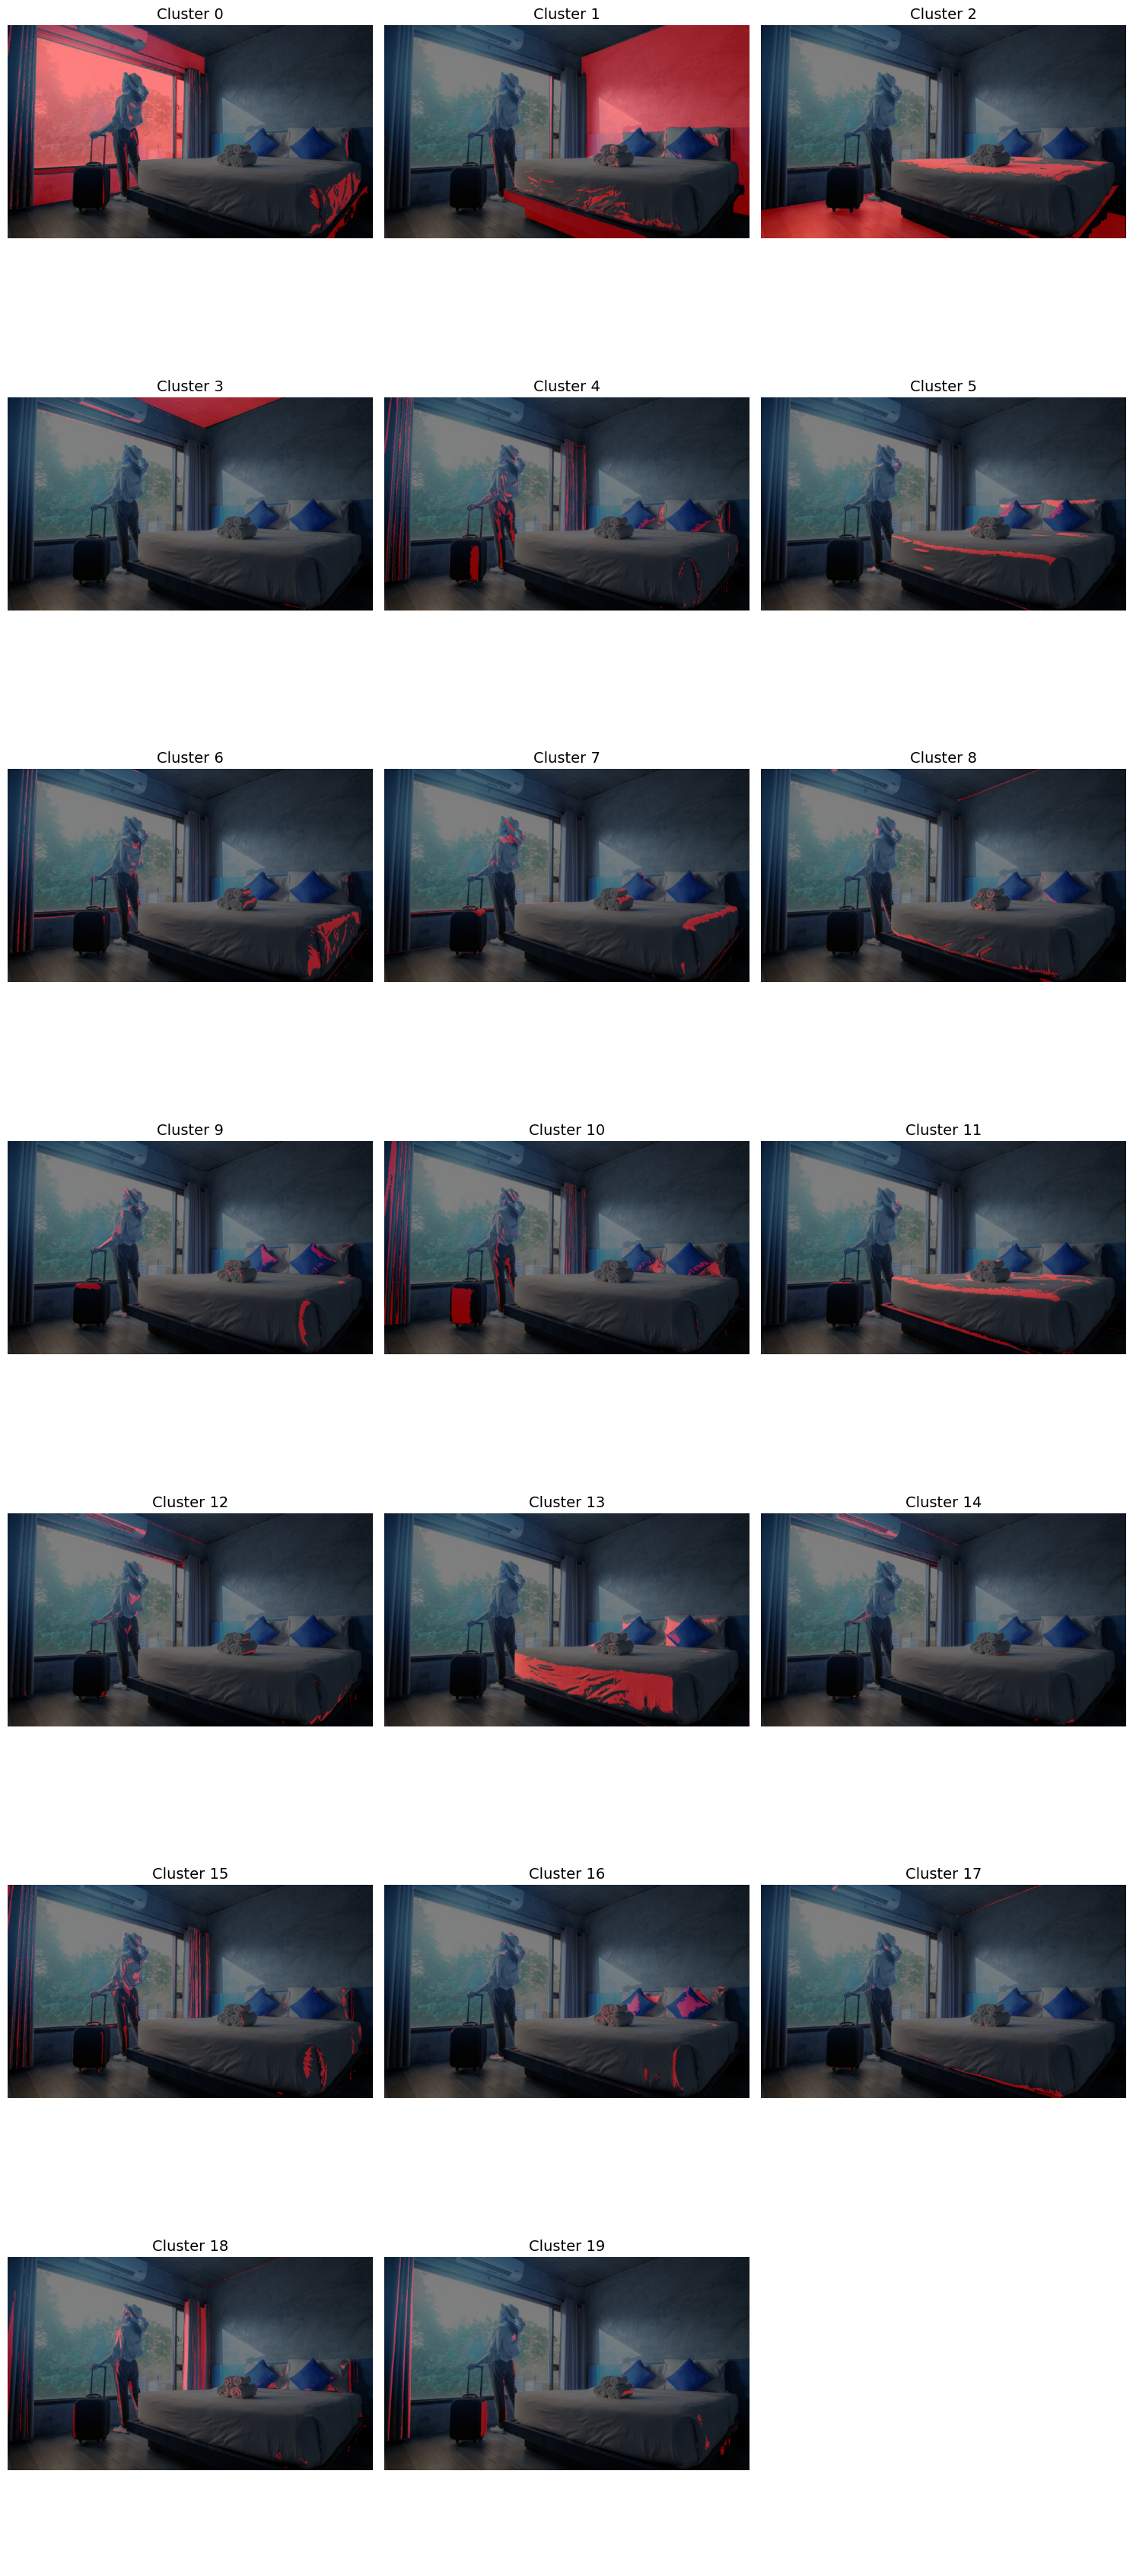

In [27]:
# Assuming you have: original_img, labels from KMeans, and n_clusters
visualize_all_clusters(img, labels, n_clusters=20, alpha=0.5)

## Connected Components in each Cluster

Find connected groups of pixels in each Cluster so that we can separate walls from other items like window frames

### Helper Functions

In [16]:
def find_cluster_subcomponents(labels, img_shape):
    """
    Find connected components within each cluster.
    
    Parameters:
    -----------
    labels : np.ndarray
        Flattened array of cluster labels from KMeans
    img_shape : tuple
        Shape of original image (H, W) or (H, W, C)
    
    Returns:
    --------
    dict : Dictionary mapping cluster_id to its connected components info
        {
            cluster_id: {
                'num_components': int,
                'component_labels': np.ndarray (2D),
                'stats': np.ndarray,
                'centroids': np.ndarray
            }
        }
    """
    # Reshape labels to 2D
    h, w = img_shape[:2]
    labels_2d = labels.reshape(h, w)
    
    results = {}
    n_clusters = len(np.unique(labels))
    
    for cluster_id in range(n_clusters):
        # Create binary mask for this cluster
        cluster_mask = (labels_2d == cluster_id).astype(np.uint8)
        
        # Find connected components within this cluster
        num_labels, component_labels, stats, centroids = cv2.connectedComponentsWithStats(
            cluster_mask, connectivity=8
        )
        
        results[cluster_id] = {
            'num_components': num_labels - 1,  # Subtract 1 to exclude background
            'component_labels': component_labels,
            'stats': stats,  # [x, y, width, height, area] for each component
            'centroids': centroids
        }
    
    return results

In [17]:
def find_cluster_subcomponents_with_threshold(labels, img_shape, min_area_threshold_percent=1.0):
    """
    Find connected components within each cluster and filter by size threshold.
    
    Parameters:
    -----------
    labels : np.ndarray
        Flattened array of cluster labels from KMeans
    img_shape : tuple
        Shape of original image (H, W) or (H, W, C)
    min_area_threshold_percent : float
        Minimum area threshold as percentage of cluster's total area (default: 1.0%)
    
    Returns:
    --------
    dict : Dictionary mapping cluster_id to its connected components info
        {
            cluster_id: {
                'total_cluster_area': int,
                'num_significant_components': int,
                'top_5_components': list of dicts with area stats,
                'all_component_labels': np.ndarray (2D),
                'all_stats': np.ndarray,
                'all_centroids': np.ndarray
            }
        }
    """
    # Reshape labels to 2D
    h, w = img_shape[:2]
    labels_2d = labels.reshape(h, w)
    
    results = {}
    n_clusters = len(np.unique(labels))
    
    for cluster_id in range(n_clusters):
        # Create binary mask for this cluster
        cluster_mask = (labels_2d == cluster_id).astype(np.uint8)
        total_cluster_area = np.sum(cluster_mask)
        
        # Calculate minimum area threshold
        min_area = (min_area_threshold_percent / 100.0) * total_cluster_area
        
        # Find connected components within this cluster
        num_labels, component_labels, stats, centroids = cv2.connectedComponentsWithStats(
            cluster_mask, connectivity=8
        )
        
        # Filter significant components (skip index 0 which is background)
        significant_components = []
        for i in range(1, num_labels):  # Start from 1 to skip background
            area = stats[i, cv2.CC_STAT_AREA]
            if area >= min_area:
                significant_components.append({
                    'component_id': i,
                    'area': area,
                    'x': stats[i, cv2.CC_STAT_LEFT],
                    'y': stats[i, cv2.CC_STAT_TOP],
                    'width': stats[i, cv2.CC_STAT_WIDTH],
                    'height': stats[i, cv2.CC_STAT_HEIGHT],
                    'centroid_x': centroids[i, 0],
                    'centroid_y': centroids[i, 1],
                    'area_percent': (area / total_cluster_area * 100) if total_cluster_area > 0 else 0
                })
        
        # Sort by area (descending) and get top 5
        significant_components.sort(key=lambda x: x['area'], reverse=True)
        top_5 = significant_components[:5]
        
        results[cluster_id] = {
            'total_cluster_area': total_cluster_area,
            'significant_components': significant_components,
            'num_significant_components': len(significant_components),
            'top_5_components': top_5,
            'all_component_labels': component_labels,
            'all_stats': stats,
            'all_centroids': centroids
        }
    
    return results


### Finding Sub Components

In [28]:
# Usage:
subcomponents = find_cluster_subcomponents(labels, img.shape)
for cluster_id, info in subcomponents.items():
    if cluster_id < 5: 
        print(f"Cluster {cluster_id} has {info['num_components']} connected component(s).")

Cluster 0 has 514 connected component(s).
Cluster 1 has 329 connected component(s).
Cluster 2 has 106 connected component(s).
Cluster 3 has 219 connected component(s).
Cluster 4 has 639 connected component(s).


In [29]:

# Usage:
subcomponents = find_cluster_subcomponents_with_threshold(labels, img.shape, min_area_threshold_percent=5.0)
for cluster_id, info in subcomponents.items():
    if cluster_id < 5: 
        total_area_of_top_5 = sum(comp['area'] for comp in info['top_5_components'])
        print(f"\nCluster {cluster_id}:")
        print(f"  Total area: {info['total_cluster_area']} pixels")
        print(f"  % area covered by top 5 components: {100*total_area_of_top_5/info['total_cluster_area']:.2f}%")
        print(f"  Significant components (>= threshold): {info['num_significant_components']}")
        print(f"  Top 5 components:")
        for i, comp in enumerate(info['top_5_components'], 1):
            print(f"    {i}. Area: {comp['area']} pixels ({comp['area_percent']:.2f}%), "
                f"Position: ({comp['x']}, {comp['y']}), Size: {comp['width']}x{comp['height']}")


Cluster 0:
  Total area: 212458 pixels
  % area covered by top 5 components: 83.09%
  Significant components (>= threshold): 4
  Top 5 components:
    1. Area: 129375 pixels (60.89%), Position: (87, 40), Size: 457x430
    2. Area: 18493 pixels (8.70%), Position: (96, 0), Size: 486x164
    3. Area: 16526 pixels (7.78%), Position: (306, 0), Size: 341x169
    4. Area: 12141 pixels (5.71%), Position: (84, 484), Size: 133x109

Cluster 1:
  Total area: 228614 pixels
  % area covered by top 5 components: 94.40%
  Significant components (>= threshold): 2
  Top 5 components:
    1. Area: 191322 pixels (83.69%), Position: (648, 0), Size: 552x627
    2. Area: 24500 pixels (10.72%), Position: (390, 539), Size: 478x161

Cluster 2:
  Total area: 88795 pixels
  % area covered by top 5 components: 92.86%
  Significant components (>= threshold): 3
  Top 5 components:
    1. Area: 56158 pixels (63.24%), Position: (0, 549), Size: 626x151
    2. Area: 18973 pixels (21.37%), Position: (445, 432), Size: 64

## Filtering Subcomponents based on Wall-Confidence Score

### Helper Functions for Wall-Confidence Score based Filtering

In [20]:
def extract_wall_components(
    subcomponents,
    wall_confidence,
    wall_confidence_threshold=0.9
):
    """
    Extract wall components from cluster subcomponents based on wall confidence.
    
    Parameters:
    -----------
    subcomponents : dict
        Dictionary from find_cluster_subcomponents_with_threshold() containing
        cluster_id -> {'significant_components', 'all_component_labels', ...}
    wall_confidence : np.ndarray
        2D array of wall confidence scores (from SegFormer .npy file)
    wall_confidence_threshold : float, optional
        Minimum average confidence to classify as wall (default: 0.9)
    
    Returns:
    --------
    list of dict
        Flat list of wall components, each containing:
        - wall_id: Sequential identifier
        - cluster_id: Source cluster
        - component_id: Component ID within cluster
        - area, x, y, width, height: Component geometry
        - centroid_x, centroid_y: Component centroid
        - area_percent: Percentage of cluster area
        - avg_wall_confidence: Average wall confidence score
        - pixel_mask: Binary mask of component pixels
    """
    wall_components = []
    wall_id = 0
    
    # Iterate over all clusters
    for cluster_id, cluster_info in subcomponents.items():
        component_labels = cluster_info['all_component_labels']
        significant_components = cluster_info['significant_components']
        
        # Iterate over all significant components in this cluster
        for component in significant_components:
            component_id = component['component_id']
            
            # Create binary mask for this component
            pixel_mask = (component_labels == component_id)
            
            # Calculate average wall confidence for pixels in this component
            component_wall_confidences = wall_confidence[pixel_mask]
            avg_confidence = component_wall_confidences.mean()
            
            # Check if component qualifies as a wall
            if avg_confidence >= wall_confidence_threshold:
                # Create wall component dictionary
                wall_component = {
                    'wall_id': wall_id,
                    'cluster_id': cluster_id,
                    'component_id': component_id,
                    'area': component['area'],
                    'x': component['x'],
                    'y': component['y'],
                    'width': component['width'],
                    'height': component['height'],
                    'centroid_x': component['centroid_x'],
                    'centroid_y': component['centroid_y'],
                    'area_percent': component['area_percent'],
                    'avg_wall_confidence': float(avg_confidence),
                    'pixel_mask': pixel_mask
                }
                
                wall_components.append(wall_component)
                wall_id += 1
    
    return wall_components

In [21]:
def overlay_wall_component_on_image(original_img, wall_component, overlay_color=[255, 0, 0], alpha=0.5):
    """
    Overlay a specific wall component on the original image for visualization.
    
    Parameters:
    -----------
    original_img : np.ndarray
        Original image (H, W, 3)
    wall_component : dict
        Wall component dictionary containing 'pixel_mask' key
    overlay_color : list or np.ndarray
        RGB color for the overlay (default: red [255, 0, 0])
    alpha : float
        Transparency of overlay (0.0 = transparent, 1.0 = opaque, default: 0.5)
    
    Returns:
    --------
    np.ndarray : Image with wall component overlay
    """
    # Create a copy of the original image
    overlay_img = original_img.copy().astype(np.float32)
    
    # Get the pixel mask from wall component
    pixel_mask = wall_component['pixel_mask']
    
    # Create overlay
    overlay_layer = np.zeros_like(overlay_img)
    overlay_layer[pixel_mask] = overlay_color
    
    # Blend original image with overlay
    result = cv2.addWeighted(overlay_img, 1 - alpha, overlay_layer, alpha, 0)
    
    return result.astype(np.uint8)


### Finding Wall Components

In [30]:
# Load wall confidence from SegFormer output
wall_confidence = np.load(wall_conf_path)

# Extract wall components
wall_components = extract_wall_components(
    subcomponents, 
    wall_confidence, 
    wall_confidence_threshold=0.5
)

# Iterate over wall components
for wall in wall_components:
    print(f"Wall {wall['wall_id']} from cluster {wall['cluster_id']}:")
    print(f"  Area: {wall['area']} pixels")
    print(f"  Position: ({wall['x']}, {wall['y']})")
    print(f"  Size: {wall['width']}x{wall['height']}")
    print(f"  Wall confidence: {wall['avg_wall_confidence']:.3f}")
    
    # Access the pixel mask
    mask = wall['pixel_mask']
    # Use mask for visualization, analysis, etc.

Wall 0 from cluster 0:
  Area: 18493 pixels
  Position: (96, 0)
  Size: 486x164
  Wall confidence: 0.633
Wall 1 from cluster 0:
  Area: 16526 pixels
  Position: (306, 0)
  Size: 341x169
  Wall confidence: 0.927
Wall 2 from cluster 0:
  Area: 12141 pixels
  Position: (84, 484)
  Size: 133x109
  Wall confidence: 0.935
Wall 3 from cluster 1:
  Area: 191322 pixels
  Position: (648, 0)
  Size: 552x627
  Wall confidence: 0.924
Wall 4 from cluster 3:
  Area: 1793 pixels
  Position: (197, 7)
  Size: 246x76
  Wall confidence: 0.811
Wall 5 from cluster 8:
  Area: 716 pixels
  Position: (647, 12)
  Size: 238x94
  Wall confidence: 0.723
Wall 6 from cluster 12:
  Area: 1387 pixels
  Position: (285, 0)
  Size: 172x81
  Wall confidence: 0.737
Wall 7 from cluster 14:
  Area: 2151 pixels
  Position: (247, 0)
  Size: 202x80
  Wall confidence: 0.751
Wall 8 from cluster 14:
  Area: 472 pixels
  Position: (275, 0)
  Size: 139x52
  Wall confidence: 0.818
Wall 9 from cluster 17:
  Area: 397 pixels
  Position

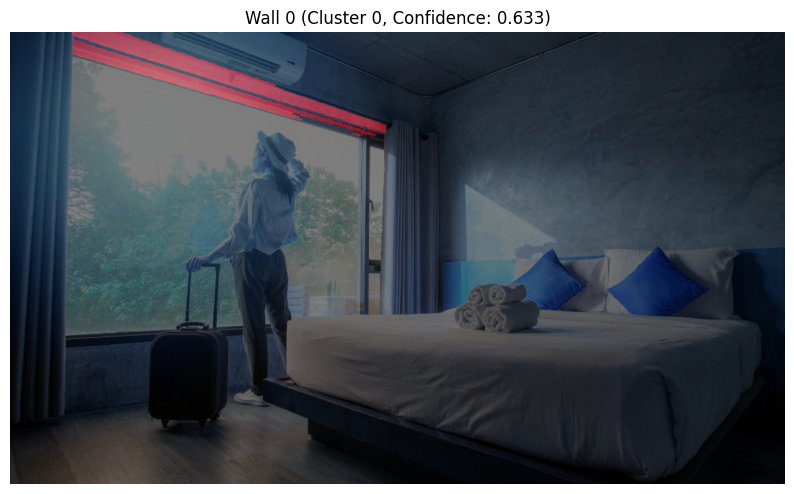

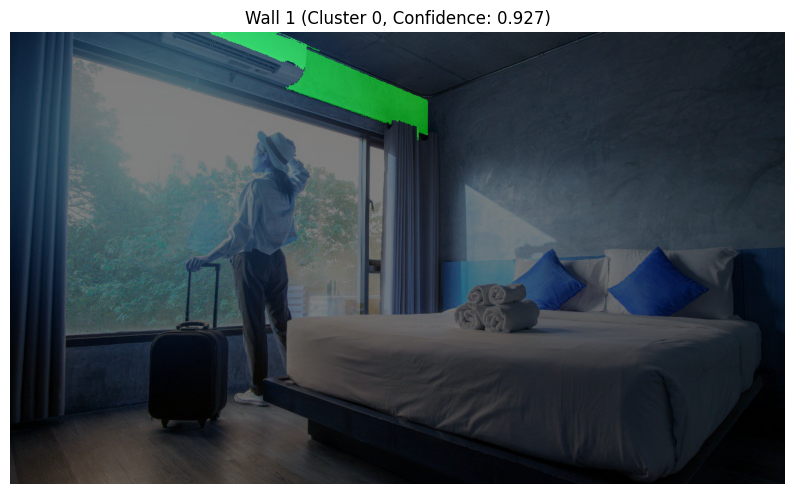

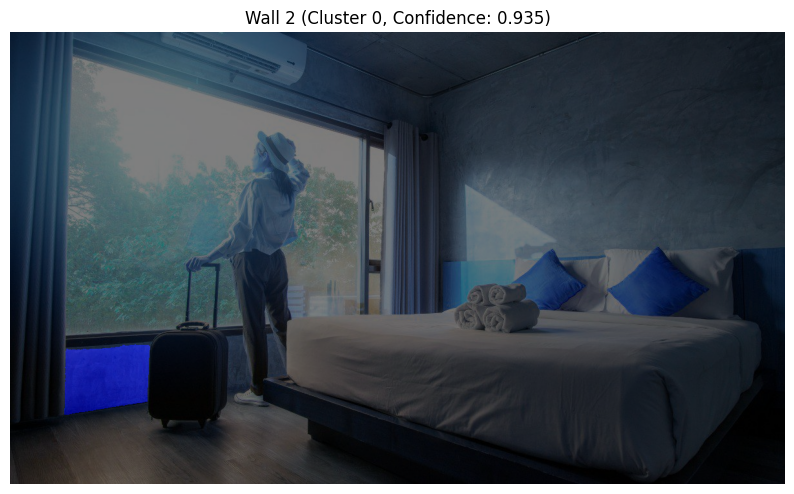

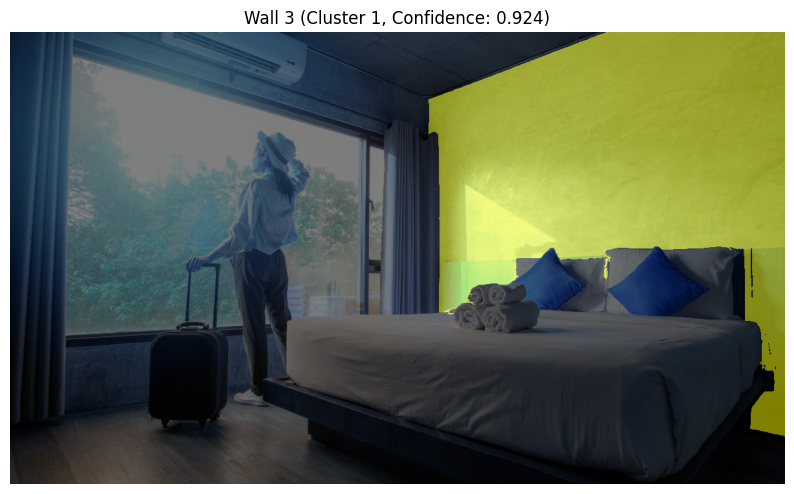

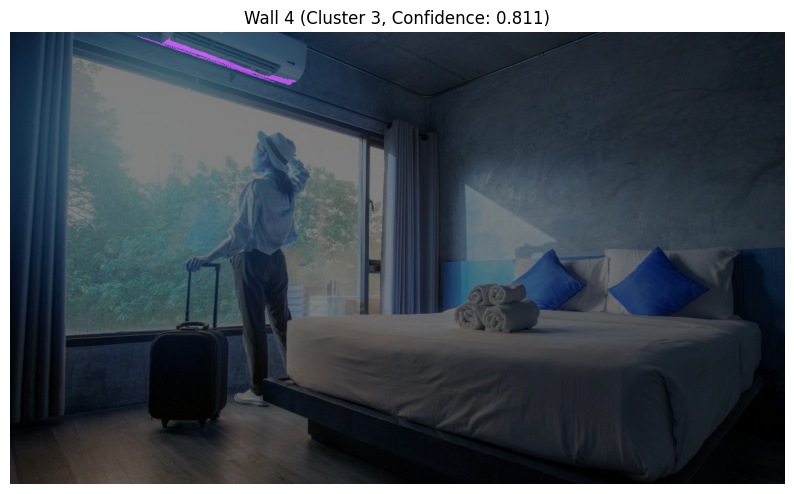

In [31]:
# Or visualize all walls with different colors
colors = [[255, 0, 0], [0, 255, 0], [0, 0, 255], [255, 255, 0], [255, 0, 255]]
for i, wall in enumerate(wall_components[:5]):
    wall_overlay = overlay_wall_component_on_image(
        img, 
        wall, 
        overlay_color=colors[i % len(colors)],
        alpha=0.5
    )
    plt.figure(figsize=(10, 8))
    plt.imshow(wall_overlay)
    plt.title(f"Wall {wall['wall_id']} (Cluster {wall['cluster_id']}, Confidence: {wall['avg_wall_confidence']:.3f})")
    plt.axis('off')
    plt.show()